## 0: import data

In [569]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from scipy.stats import trim_mean

netflix = pd.read_csv("../content_libraries/netflix_2022/netflix_titles_2022.csv")
amazon = pd.read_csv("../content_libraries/amazon_2022/amazon_titles_2022.csv")

## 1.0: Info on the netflix dataset

In [570]:
netflix.head()
netflix.info()
netflix.describe()


<class 'pandas.DataFrame'>
RangeIndex: 5850 entries, 0 to 5849
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    5850 non-null   str    
 1   title                 5849 non-null   str    
 2   type                  5850 non-null   str    
 3   description           5832 non-null   str    
 4   release_year          5850 non-null   int64  
 5   age_certification     3231 non-null   str    
 6   runtime               5850 non-null   int64  
 7   genres                5850 non-null   str    
 8   production_countries  5850 non-null   str    
 9   seasons               2106 non-null   float64
 10  imdb_id               5447 non-null   str    
 11  imdb_score            5368 non-null   float64
 12  imdb_votes            5352 non-null   float64
 13  tmdb_popularity       5759 non-null   float64
 14  tmdb_score            5539 non-null   float64
dtypes: float64(5), int64(2), str(8)


,release_year,runtime,seasons,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
count,5850.000000,5850.000000,2106.000000,5368.000000,5.352000e+03,5759.000000,5539.000000
mean,2016.417094,76.888889,2.162868,6.510861,2.343938e+04,22.637925,6.829175
std,6.937726,39.002509,2.689041,1.163826,9.582047e+04,81.680263,1.170391
min,1945.000000,0.000000,1.000000,1.500000,5.000000e+00,0.009442,0.500000
25%,2016.000000,44.000000,1.000000,5.800000,5.167500e+02,2.728500,6.100000
50%,2018.000000,83.000000,1.000000,6.600000,2.233500e+03,6.821000,6.900000
75%,2020.000000,104.000000,2.000000,7.300000,9.494000e+03,16.590000,7.537500
max,2022.000000,240.000000,42.000000,9.600000,2.294231e+06,2274.044000,10.000000


(5850, 15)
Index(['id', 'title', 'type', 'description', 'release_year',
       'age_certification', 'runtime', 'genres', 'production_countries',
       'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity',
       'tmdb_score'],
      dtype='str')
id                         0
title                      1
type                       0
description               18
release_year               0
age_certification       2619
runtime                    0
genres                     0
production_countries       0
seasons                 3744
imdb_id                  403
imdb_score               482
imdb_votes               498
tmdb_popularity           91
tmdb_score               311
dtype: int64


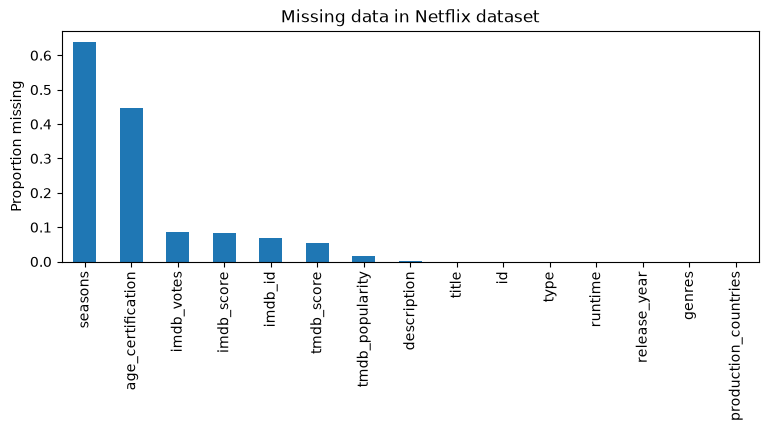

In [571]:
# how many null values?
print(netflix.shape)
print(netflix.columns)
print(netflix.isna().sum())


missing_netflix = netflix.isnull().mean().sort_values(ascending=False)

missing_netflix.plot(kind="bar", figsize=(9,3))
plt.ylabel("Proportion missing")
plt.title("Missing data in Netflix dataset")
plt.show()

##  1.1: Info on the amazon dataset

In [572]:
amazon.head()
amazon.info()
amazon.describe()

<class 'pandas.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   str    
 1   title                 9871 non-null   str    
 2   type                  9871 non-null   str    
 3   description           9752 non-null   str    
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   str    
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   str    
 8   production_countries  9871 non-null   str    
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   str    
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float64
dtypes: float64(5), int64(2), str(8)


,release_year,runtime,seasons,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
count,9871.000000,9871.000000,1357.000000,8850.000000,8.840000e+03,9324.000000,7789.000000
mean,2001.327221,85.973052,2.791452,5.976395,8.533614e+03,6.910204,5.984247
std,25.810071,33.512466,4.148958,1.343842,4.592015e+04,30.004098,1.517986
min,1912.000000,1.000000,1.000000,1.100000,5.000000e+00,0.000011,0.800000
25%,1995.500000,65.000000,1.000000,5.100000,1.170000e+02,1.232000,5.100000
50%,2014.000000,89.000000,1.000000,6.100000,4.625000e+02,2.536000,6.000000
75%,2018.000000,102.000000,3.000000,6.900000,2.236250e+03,5.634000,6.900000
max,2022.000000,549.000000,51.000000,9.900000,1.133692e+06,1437.906000,10.000000


(9871, 15)
Index(['id', 'title', 'type', 'description', 'release_year',
       'age_certification', 'runtime', 'genres', 'production_countries',
       'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity',
       'tmdb_score'],
      dtype='str')
id                         0
title                      0
type                       0
description              119
release_year               0
age_certification       6487
runtime                    0
genres                     0
production_countries       0
seasons                 8514
imdb_id                  667
imdb_score              1021
imdb_votes              1031
tmdb_popularity          547
tmdb_score              2082
dtype: int64


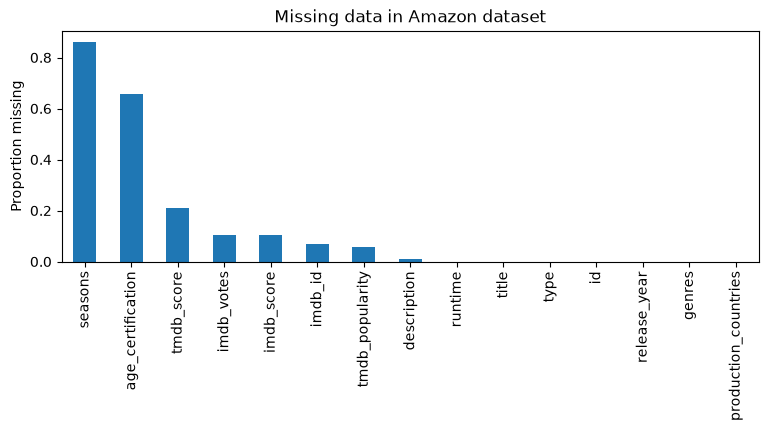

In [573]:
# how many null values?
print(amazon.shape)
print(amazon.columns)
print(amazon.isna().sum())

missing_amazon = amazon.isnull().mean().sort_values(ascending=False)

missing_amazon.plot(kind="bar", figsize=(9,3))
plt.ylabel("Proportion missing")
plt.title("Missing data in Amazon dataset")
plt.show()

## 2.0: Combine the two datasets

In [574]:
netflix["service"] = "Netflix"
amazon["service"] = "Amazon Prime"
catalog = pd.concat([netflix, amazon], ignore_index=True)


# change to numeric values to be certain they gets read correctly
catalog["release_year"] = pd.to_numeric(
    catalog["release_year"], errors="coerce"
)

catalog["imdb_score"] = pd.to_numeric(
    catalog["imdb_score"], errors="coerce"
)

catalog["imdb_votes"] = pd.to_numeric(
    catalog["imdb_votes"], errors="coerce"
)

catalog["content_age"] = 2022 - catalog["release_year"]


## 3.0: Distribution of movies and TV shows for both services


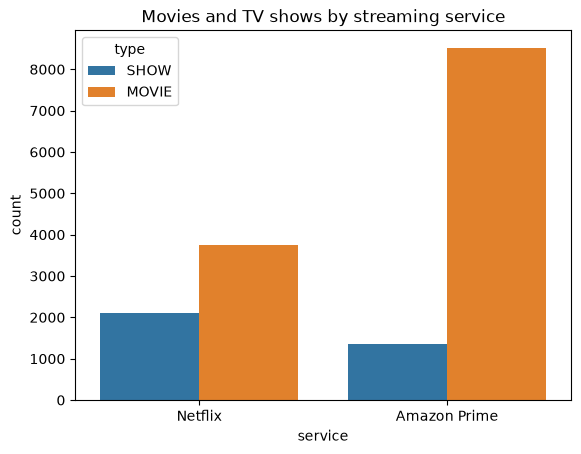

type          MOVIE  SHOW
service                  
Amazon Prime   8514  1357
Netflix        3744  2106


In [575]:
sns.countplot(data=catalog, x="service", hue="type")
plt.title("Movies and TV shows by streaming service")
plt.show()

print(catalog.groupby(["service", "type"]).size().unstack(fill_value=0))

## 3.1 Percentage of difference in moive and series for each service

In [576]:
pd.crosstab(
    catalog["service"],
    catalog["type"],
    normalize="index"
) * 100

type,MOVIE,SHOW
service,,
Amazon Prime,86.252659,13.747341
Netflix,64.000000,36.000000


note: Netflix's 2022 catalog consisted of 64% movies and 36% TV shows, while Amazon's consisted of 86.25% and 13.75%

## 4:0 Age of the content avaliable (release- year distribution)

In [577]:

# Calculate content age
catalog["content_age"] = 2022 - catalog["release_year"]

# Compare robust and non-robust measures
age_summary = catalog.groupby("service")["content_age"].agg(
    mean="mean",
    median="median",
    count="count"
)

# Add 10% trimmed mean
trimmed_means = catalog.groupby("service")["content_age"].apply(
    lambda x: trim_mean(x.dropna(), proportiontocut=0.10)
)

age_summary["trimmed_mean"] = trimmed_means

print(age_summary.round(2))


               mean  median  count  trimmed_mean
service                                         
Amazon Prime  20.67     8.0   9871         15.36
Netflix        5.58     4.0   5850          4.16


Note: Its median content age is 8 years, compared with 4 years for Netflix. This means that half of Amazon Primes catelog was released 8 years before 2022, compared to Netlfix's 4 years before 2022. The median-mean gap of Amazon Prime, with a median of 8.0 years and a mean of 20.67 years suggests a right-skewed distribution, where a relatively small number of very old titles pull the mean upward. Netflix is less effected by extreme ages, with a trimmed mean of 4.16 years compared with a mean of 5.58 years. 

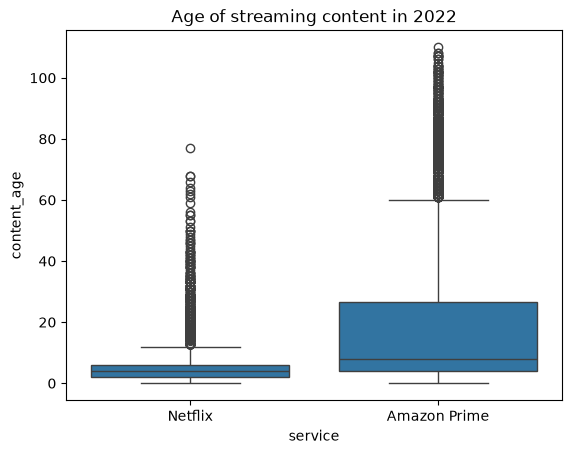

In [578]:
catalog["content_age"] = 2022 - catalog["release_year"]

sns.boxplot(data=catalog, x="service", y="content_age")
plt.title("Age of streaming content in 2022")
plt.show()


## Zoom in of the boxplot (Content age by streaming in 2022)

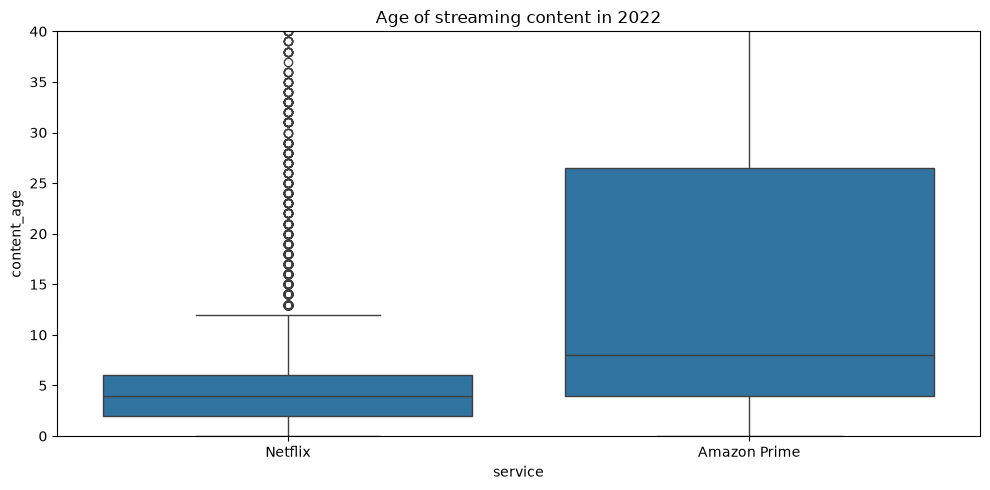

service
Amazon Prime    2001.327221
Netflix         2016.417094
Name: release_year, dtype: float64

In [579]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=catalog,
    x="service",
    y="content_age"
)

plt.ylim(0, 40)
plt.title("Age of streaming content in 2022")
plt.tight_layout()
plt.show()

# average release year
catalog.groupby("service")["release_year"].mean()

Note: From the boxplot it is shown that Amazon prime has a greater distribution spread of release years. While, Netflix's core catalog shows low variability, heavily concentrating on newer releases. 
This then make sense that the mean for Amazon prime is 2001 compared to Netflix at 2016.
Futhermore, both platforms carry a very long "tail" of classic or vintage movies and television shows. Amazon Prime simply dominates in the ultra-vintage category, hosting titles that are over a century old.


## 4.1 Distribution of new vs. older content 

content_category  New content (2018–2022)  Older content (before 2018)
service                                                               
Amazon Prime                        31.76                        68.24
Netflix                             61.21                        38.79


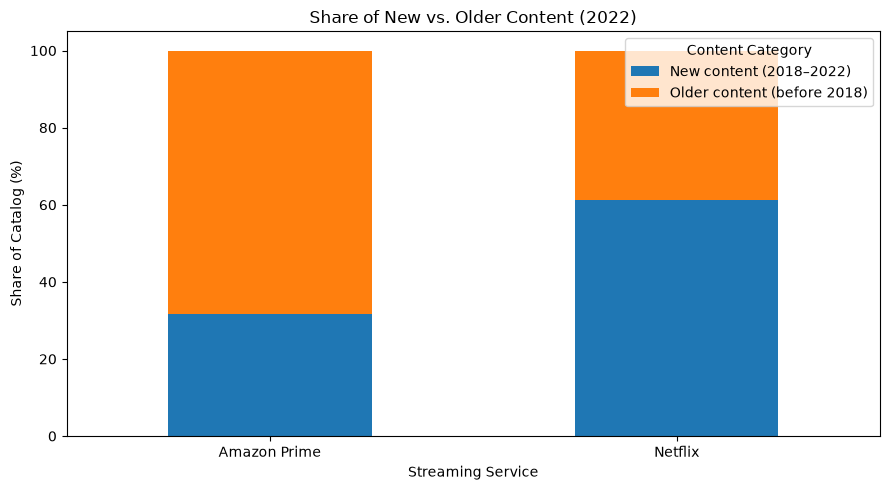

In [580]:
catalog["release_year"] = pd.to_numeric(
    catalog["release_year"], errors="coerce"
)

catalog["content_category"] = np.select(
    [
        catalog["release_year"].between(2018, 2022),
        catalog["release_year"] < 2018
    ],
    [
        "New content (2018–2022)",
        "Older content (before 2018)"
    ],
    default=None
)
content_share = pd.crosstab(
    catalog["service"],
    catalog["content_category"],
    normalize="index"
) * 100

print(content_share.round(2))

content_share.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Share of New vs. Older Content (2022)")
plt.xlabel("Streaming Service")
plt.ylabel("Share of Catalog (%)")
plt.legend(title="Content Category")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

NOTE: are older titles more highly rated than newer? 
Which service has the highest share of highly rated recent content?

## 5.0 Determine an estimate for the Vote threshold m

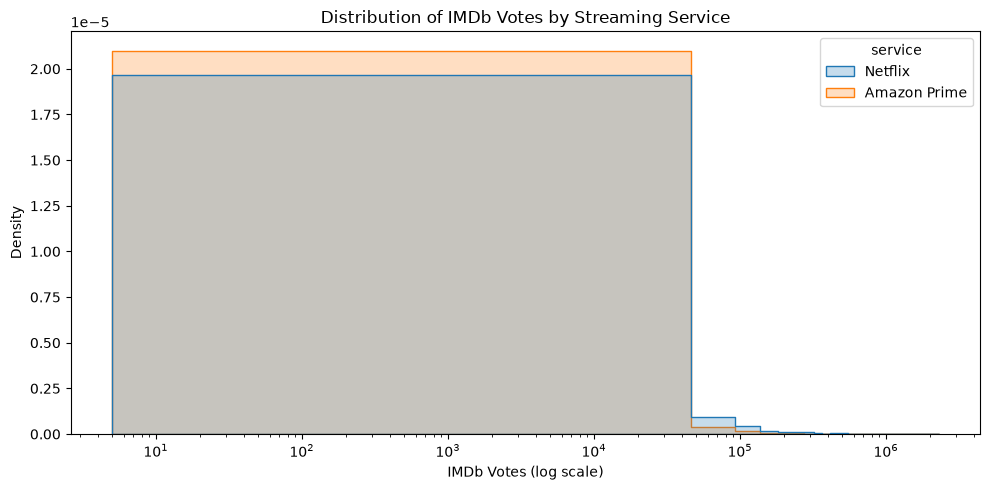

               count      mean       std  min     25%     50%      75%  \
service                                                                  
Amazon Prime  8840.0   8533.61  45920.15  5.0  117.00   462.5  2236.25   
Netflix       5352.0  23439.38  95820.47  5.0  516.75  2233.5  9494.00   

                  90%        max  
service                           
Amazon Prime  11046.7  1133692.0  
Netflix       44872.8  2294231.0  


In [581]:
# Distribution of IMDb votes by service

# Exclude missing and zero votes for the log-scale distribution
votes_data = catalog[catalog["imdb_votes"] > 0].copy()

plt.figure(figsize=(10, 5))

sns.histplot(
    data=votes_data,
    x="imdb_votes",
    hue="service",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.xscale("log")
plt.title("Distribution of IMDb Votes by Streaming Service")
plt.xlabel("IMDb Votes (log scale)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

# Descriptive statistics by service
print(
    catalog.groupby("service")["imdb_votes"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9])
    .round(2)
)


note: Identifies typical and unusually low vote counts.
Netflix titles have substantially higher IMDb vote counts than Amazon Prime titles, with a median of 2,234 votes compared with 463, although both services show highly right-skewed distributions where a small number of titles receive exceptionally high vote counts.

## 5.1 Analyse missing, zero and low vote counts

In [582]:

# Categorise vote counts, keeping missing values separate
catalog["vote_status"] = pd.cut(
    catalog["imdb_votes"],
    bins=[-np.inf, 0, 10, 50, 100, 500, 1000, np.inf],
    labels=[
        "Zero or negative",
        "1–10",
        "11–50",
        "51–100",
        "101–500",
        "501–1000",
        "1001+"
    ]
)

catalog["vote_status"] = catalog["vote_status"].cat.add_categories(
    ["Missing"]
)

catalog.loc[
    catalog["imdb_votes"].isna(), "vote_status"
] = "Missing"

# Counts by service
vote_counts = pd.crosstab(
    catalog["service"],
    catalog["vote_status"]
)

# Percentages within each service
vote_percentages = (
    pd.crosstab(
        catalog["service"],
        catalog["vote_status"],
        normalize="index"
    ) * 100
)

print("Vote-count categories (number of titles):")
print(vote_counts)

print("\nVote-count categories (% of each service's catalog):")
print(vote_percentages.round(2))


Vote-count categories (number of titles):
vote_status   1–10  11–50  51–100  101–500  501–1000  1001+  Missing
service                                                             
Amazon Prime   170    990     826     2565      1062   3227     1031
Netflix         39    221     191      857       603   3441      498

Vote-count categories (% of each service's catalog):
vote_status   1–10  11–50  51–100  101–500  501–1000  1001+  Missing
service                                                             
Amazon Prime  1.72  10.03    8.37    25.99     10.76  32.69    10.44
Netflix       0.67   3.78    3.26    14.65     10.31  58.82     8.51


note: Shows the number and proportion of titles with low, high, or missing IMDb votes. Amazon Prime has a larger share of titles with fewer than 500 votes, while Netflix has a higher share with over 1,000 votes (58.82% vs. 32.69%), suggesting greater IMDb voting activity for Netflix titles.

## 5.2 Rating stability at different vote levels

In [583]:

votes_data = catalog[
    catalog["imdb_votes"].notna() &
    (catalog["imdb_votes"] > 0)
].copy()

# Define vote-count ranges
bins = [0, 10, 50, 100, 500, 1000, 5000, np.inf]

labels = [
    "1–10",
    "11–50",
    "51–100",
    "101–500",
    "501–1000",
    "1001–5000",
    "5001+"
]

# Use right=False for left-inclusive, right-exclusive intervalss
votes_data["vote_group"] = pd.cut(
    votes_data["imdb_votes"],
    bins=[1, 11, 51, 101, 501, 1001, 5001, np.inf],
    labels=labels,
    right=False
)

# Summarize IMDb ratings within each service and vote group
rating_summary = votes_data.groupby(
    ["service", "vote_group"], observed=False
)["imdb_score"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std"
)

print(rating_summary.round(2))


                         count  mean  median   std
service      vote_group                           
Amazon Prime 1–10          170  6.45     6.6  1.43
             11–50         990  6.18     6.3  1.49
             51–100        826  6.01     6.0  1.29
             101–500      2565  5.55     5.6  1.32
             501–1000     1062  5.68     5.7  1.23
             1001–5000    1796  6.04     6.2  1.23
             5001+        1431  6.67     6.8  1.15
Netflix      1–10           39  6.54     6.4  1.32
             11–50         221  6.37     6.5  1.37
             51–100        191  6.21     6.4  1.25
             101–500       857  6.08     6.2  1.17
             501–1000      603  6.27     6.5  1.10
             1001–5000    1583  6.52     6.6  1.09
             5001+        1858  6.82     6.9  1.12


note: Compares IMDb ratings across vote-count groups. Netflix has consistently higher average ratings than Amazon Prime, and both services show their highest ratings among titles with over 5,000 votes, although the relationship is not consistently increasing across all groups.

## 5.2 Find a minimum-vote threshold m

In [584]:


thresholds = [0, 10, 50, 100, 250, 500, 1000, 2500, 5000]

data = catalog[
    catalog["imdb_votes"].notna()
    & (catalog["imdb_votes"] > 0)
    & catalog["imdb_score"].notna()
].copy()

results = []

for threshold in thresholds:
    for service, service_data in data.groupby("service"):
        subset = service_data[
            service_data["imdb_votes"] >= threshold
        ]

        results.append({
            "service": service,
            "minimum_votes": threshold,
            "number_of_titles": len(subset),
            "mean_score": subset["imdb_score"].mean(),
            "median_score": subset["imdb_score"].median(),
            "std_score": subset["imdb_score"].std()
        })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(2).to_string(index=False))

# Compare the mean rating difference between services
comparison = threshold_results.pivot(
    index="minimum_votes",
    columns="service",
    values="mean_score"
)

comparison["Netflix_minus_Amazon"] = (
    comparison["Netflix"] - comparison["Amazon Prime"]
)

print("\nMean rating difference:")
print(comparison.round(3))


     service  minimum_votes  number_of_titles  mean_score  median_score  std_score
Amazon Prime              0              8840        5.98           6.1       1.34
     Netflix              0              5352        6.51           6.6       1.16
Amazon Prime             10              8697        5.97           6.0       1.34
     Netflix             10              5319        6.51           6.6       1.16
Amazon Prime             50              7703        5.94           6.0       1.32
     Netflix             50              5098        6.52           6.6       1.15
Amazon Prime            100              6865        5.93           6.0       1.32
     Netflix            100              4902        6.53           6.6       1.15
Amazon Prime            250              5417        6.05           6.1       1.29
     Netflix            250              4506        6.57           6.7       1.14
Amazon Prime            500              4292        6.16           6.3       1.27
    

## 5.3 Calculate weighted IMdb ratings with m being 100, 500 and 1000

In [585]:
# Keep titles with a recorded IMDb score and vote count
weighted_data = catalog.loc[
    catalog["imdb_score"].notna()
    & catalog["imdb_votes"].notna()
    & (catalog["imdb_votes"] >= 0)
].copy()

# Shared average rating across both services
C = weighted_data["imdb_score"].mean()

print(f"Overall IMDb average (C): {C:.3f}")

# Calculate Bayesian weighted ratings for each candidate m
for m in [100, 500, 1000]:
    weighted_data[f"weighted_rating_m{m}"] = (
        (weighted_data["imdb_votes"] /
         (weighted_data["imdb_votes"] + m))
        * weighted_data["imdb_score"]
        +
        (m /
         (weighted_data["imdb_votes"] + m))
        * C
    )

# Compare raw and weighted ratings by service
summary = weighted_data.groupby("service").agg(
    number_of_titles=("imdb_score", "count"),
    raw_mean=("imdb_score", "mean"),
    raw_median=("imdb_score", "median"),
    weighted_mean_m100=("weighted_rating_m100", "mean"),
    weighted_mean_m500=("weighted_rating_m500", "mean"),
    weighted_mean_m1000=("weighted_rating_m1000", "mean")
)

print("\nRating comparison by service:")
print(summary.round(3))


Overall IMDb average (C): 6.178

Rating comparison by service:
              number_of_titles  raw_mean  raw_median  weighted_mean_m100  \
service                                                                    
Amazon Prime              8840     5.977         6.1               6.047   
Netflix                   5352     6.511         6.6               6.499   

              weighted_mean_m500  weighted_mean_m1000  
service                                                
Amazon Prime               6.141                6.178  
Netflix                    6.481                6.462  


In [586]:

rating_columns = {
    "Raw": "imdb_score",
    "m = 100": "weighted_rating_m100",
    "m = 500": "weighted_rating_m500",
    "m = 1000": "weighted_rating_m1000"
}

gap_results = []

for label, column in rating_columns.items():
    means = weighted_data.groupby("service")[column].mean()

    gap_results.append({
        "method": label,
        "Amazon Prime mean": means["Amazon Prime"],
        "Netflix mean": means["Netflix"],
        "Netflix minus Amazon": (
            means["Netflix"] - means["Amazon Prime"]
        )
    })

gap_table = pd.DataFrame(gap_results)

print(gap_table.round(3).to_string(index=False))


  method  Amazon Prime mean  Netflix mean  Netflix minus Amazon
     Raw              5.977         6.511                 0.534
 m = 100              6.047         6.499                 0.452
 m = 500              6.141         6.481                 0.340
m = 1000              6.178         6.462                 0.284


note: The Bayesian weighting parameter (\(m\)) was investigated by comparing mean IMDb ratings using values of 100, 500, and 1,000, with the overall mean rating (\(C=6.178\)) used as the reference point. As \(m\) increased, the rating difference between Netflix and Amazon Prime decreased, demonstrating the importance of selecting a justified value of \(m\) and checking the robustness of the results across different values.

## 6.0 Content quality based on imdb rating

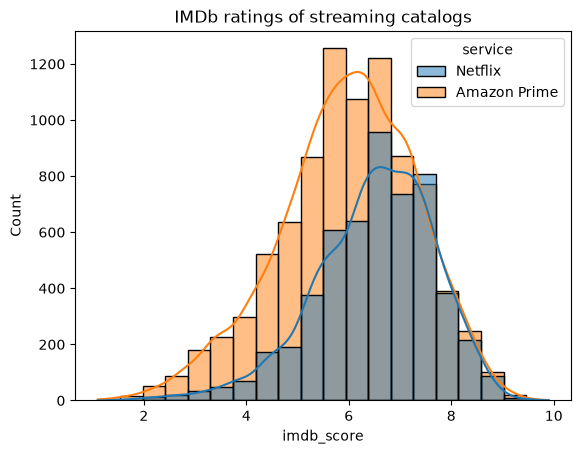

,mean,median,std,count
service,,,,
Amazon Prime,5.976395,6.1,1.343842,8850
Netflix,6.510861,6.6,1.163826,5368


In [587]:
sns.histplot(
    data=catalog,
    x="imdb_score",
    hue="service",
    kde=True,
    bins=20
)

plt.title("IMDb ratings of streaming catalogs")
plt.show()


catalog.groupby("service")["imdb_score"].agg(
    ["mean", "median", "std", "count"]
)

# not sufficent: if catelog increases but the number of high-rated titels
# stay the same, it should not be punished with a lower average rating

## 6.1  Create upper bound for high-quality content measure

In [588]:

# Define what high_quality is in this case
catalog["high_quality"] = (
    (catalog["imdb_score"] >= 7) &
    (catalog["imdb_votes"] >= 200)
)

high_quality_stats = (
    catalog.groupby("service")
    .agg(
        total_titles=("imdb_id", "count"),
        high_quality_titles=("high_quality", "sum"),
        high_quality_share=("high_quality", "mean")
    )
)

high_quality_stats["high_quality_share"] *= 100

high_quality_stats.round(2)

# - high_quality_share:
#   What proportion of the catalog is highly rated? 
# - high_quality_titels:
# How many highly rated titles can consumers access?


# explores the idea of The average rating might barely change,
# but the amount of highly rated content available per title has decreased?


,total_titles,high_quality_titles,high_quality_share
service,,,
Amazon Prime,9204,1445,14.64
Netflix,5447,1859,31.78


In [589]:
# Bayesian/weight rating 
# - we give more weight to imdb scores that have more reviews

# Overall average IMDb score
C = 6.178

# prior strength: the title's own IMDb score and the overall average each get roughly 50% weight(needs defined)
m = 1000

# Bayesian weighted IMDb score
catalog["weighted_imdb"] = (
    (catalog["imdb_votes"] / (catalog["imdb_votes"] + m))
    * catalog["imdb_score"]
    +
    (m / (catalog["imdb_votes"] + m))
    * C
)

catalog.groupby("service")["weighted_imdb"].mean().round(2)

service
Amazon Prime    6.18
Netflix         6.46
Name: weighted_imdb, dtype: float64

In [590]:
# answers: What is the overall quality of the catalog when we account for the reliability of IMDb ratings?
quality_comparison = (
    catalog.groupby("service")
    .agg(
        number_of_titles=("imdb_id", "count"),
        average_imdb=("imdb_score", "mean"),
        average_weighted_imdb=("weighted_imdb", "mean"),
        median_imdb_votes=("imdb_votes", "median"),
        high_quality_titles=("high_quality", "sum"),
        high_quality_share=("high_quality", "mean")
    )
)

quality_comparison["high_quality_share"] *= 100

quality_comparison.round(2)

,number_of_titles,average_imdb,average_weighted_imdb,median_imdb_votes,high_quality_titles,high_quality_share
service,,,,,,
Amazon Prime,9204,5.98,6.18,462.5,1445,14.64
Netflix,5447,6.51,6.46,2233.5,1859,31.78


## 7.0 Genre distribution across services

In [591]:

catalog["genres"] = catalog["genres"].fillna("[]")
catalog["genres"] = catalog["genres"].apply(ast.literal_eval)

genres = catalog.explode("genres")

genres["genres"] = genres["genres"].str.strip()

# number of movies and tv shows in each genre
genre_counts = genres.groupby("genres").size().sort_values(ascending=False)

print(genre_counts)


genres
drama            7732
comedy           5312
thriller         3347
action           2977
romance          2723
crime            2187
documentation    2048
horror           1443
family           1433
scifi            1294
fantasy          1184
animation        1180
european         1155
music             700
history           650
western           531
war               487
sport             398
reality           372
dtype: int64


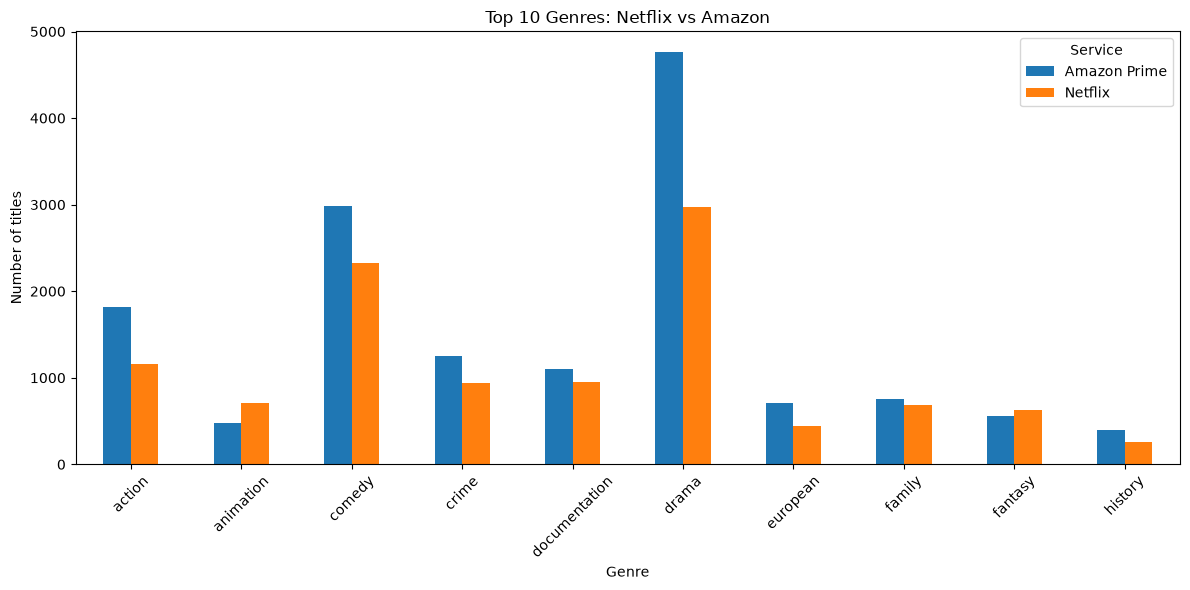

In [592]:
# number of tv shows and movies accros genres
# note: a movie or a show can have multiple genres
genre_counts = genres.groupby(["genres", "service"]).size().unstack(fill_value=0)

genre_counts.head(10).plot(kind="bar", figsize=(12, 6))

plt.xlabel("Genre")
plt.ylabel("Number of titles")
plt.title("Top 10 Genres: Netflix vs Amazon")
plt.xticks(rotation=45)
plt.legend(title="Service")
plt.tight_layout()
plt.show()

## 7.1 Which genre provide the highest-quality content?

In [593]:
# based om imdb_score
genre_ratings = (
    genres.groupby(["genres", "service"])["imdb_score"]
    .mean()
    .unstack()
)

genre_ratings


service,Amazon Prime,Netflix
genres,,
action,5.671824,6.420920
animation,6.507143,6.702063
comedy,5.994900,6.394319
crime,6.000165,6.650385
documentation,6.994837,7.009197
drama,6.132034,6.624620
european,6.308023,6.529673
family,6.147652,6.332362
fantasy,5.937009,6.558158


In [594]:
# based on the baysian weighted score
genre_ratings_weighted = (
    genres.groupby(["genres", "service"])["weighted_imdb"]
    .mean()
    .unstack()
    .round(2)
)
genre_ratings_weighted

service,Amazon Prime,Netflix
genres,,
action,6.10,6.43
animation,6.34,6.55
comedy,6.19,6.41
crime,6.27,6.60
documentation,6.42,6.70
drama,6.29,6.56
european,6.38,6.51
family,6.19,6.33
fantasy,6.13,6.54


## 7.2 drama movies versus drama series across Netflix and Amazon Prime

In [595]:
# Count drama movies and series
drama = genres[
    genres["genres"].str.lower() == "drama"
].copy()

drama_counts = pd.crosstab(
    drama["service"],
    drama["type"]
)

print(drama_counts)


type          MOVIE  SHOW
service                  
Amazon Prime   4226   538
Netflix        1876  1092


In [596]:
# Check sample sizes for IMDb ratings
drama_summary = (
    drama.groupby(["service", "type"])
    .agg(
        total_titles=("title", "nunique"),
        rated_titles=("imdb_score", "count"),
        mean_rating=("imdb_score", "mean"),
        median_rating=("imdb_score", "median"),
        std_rating=("imdb_score", "std")
    )
    .round(2)
)

print(drama_summary)


                    total_titles  rated_titles  mean_rating  median_rating  \
service      type                                                            
Amazon Prime MOVIE          4191          4007         5.99            6.0   
             SHOW            537           482         7.29            7.4   
Netflix      MOVIE          1865          1805         6.31            6.4   
             SHOW           1087          1022         7.19            7.3   

                    std_rating  
service      type               
Amazon Prime MOVIE        1.14  
             SHOW         1.00  
Netflix      MOVIE        1.08  
             SHOW         0.96  


note: The original IMDb ratings show that drama series receive higher ratings than drama movies on both platforms. The difference is larger on Amazon Prime, where series average 7.29 compared with 5.99 for movies, than on Netflix, where the averages are 7.19 and 6.31. Netflix has higher-rated drama movies on average, while Amazon Prime series score slightly higher. Keep in mind there is more IMDb votes for Netflix then Amazon Prime

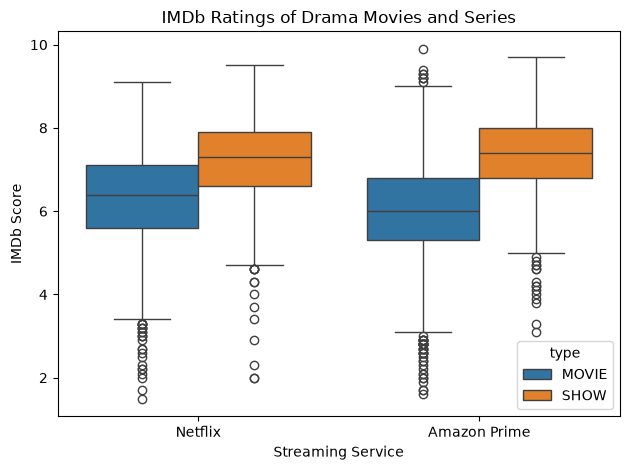

In [597]:
# Compare IMDb ratings
sns.boxplot(
    data=drama.dropna(subset=["imdb_score"]),
    x="service",
    y="imdb_score",
    hue="type"
)

plt.title("IMDb Ratings of Drama Movies and Series")
plt.xlabel("Streaming Service")
plt.ylabel("IMDb Score")
plt.tight_layout()
plt.show()

In [598]:
# Compare original and weighted IMDb ratings
rating_comparison = (
    drama.groupby(["service", "type"])
    .agg(
        rated_titles=("imdb_score", "count"),
        mean_imdb=("imdb_score", "mean"),
        median_imdb=("imdb_score", "median"),
        mean_weighted=("weighted_imdb", "mean"),
        median_weighted=("weighted_imdb", "median")
    )
    .round(2)
)

print(rating_comparison)


                    rated_titles  mean_imdb  median_imdb  mean_weighted  \
service      type                                                         
Amazon Prime MOVIE          4007       5.99          6.0           6.21   
             SHOW            482       7.29          7.4           6.91   
Netflix      MOVIE          1805       6.31          6.4           6.35   
             SHOW           1022       7.19          7.3           6.94   

                    median_weighted  
service      type                    
Amazon Prime MOVIE             6.16  
             SHOW              6.73  
Netflix      MOVIE             6.27  
             SHOW              6.85  


note: Overall drama series have higher average IMDb ratings than drama movies on both platforms. After weighting, the difference decreases from 1.30 (7.29-5.99) to 0.70 points (6.21-6.91) points on Amazon Prime and from 1.06 (7.19 - 6.13) to 0.51 on Netflix. Netflix has slightly higher weighted ratings for both movies and series. This suggests that the rating gap between drama movies and series narrows when accounting for IMDb vote counts.

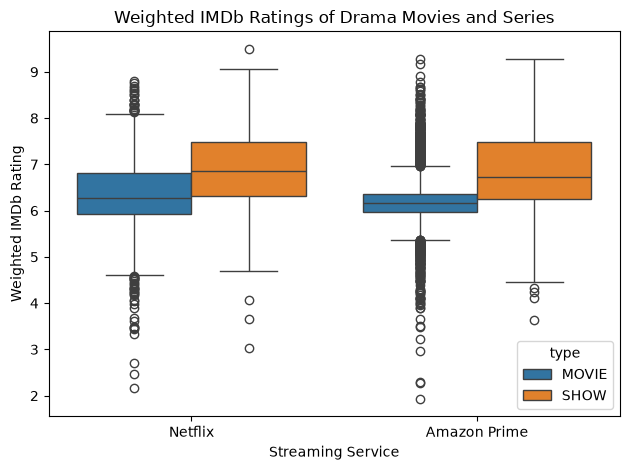

In [599]:
sns.boxplot(
    data=drama.dropna(subset=["weighted_imdb"]),
    x="service",
    y="weighted_imdb",
    hue="type"
)

plt.title("Weighted IMDb Ratings of Drama Movies and Series")
plt.xlabel("Streaming Service")
plt.ylabel("Weighted IMDb Rating")
plt.tight_layout()
plt.show()


## 8.0: Country of origin 

In [600]:
# Are streaming services increasingly relying on particular types of content?
# Are streaming services relying on content from small number of countries, or 
# are the catelogs becoming more diverse?


## 8.1 Each country's share of the catalogue


In [601]:
# Keep titles with known production countries
country_data = catalog.dropna(
    subset=["service", "production_countries"]
).copy()

# Separate co-productions into individual country assignments
country_data["production_countries"] = (
    country_data["production_countries"].str.split(",")
)

country_data = country_data.explode("production_countries")
country_data["production_countries"] = (
    country_data["production_countries"].str.strip()
)

# Count titles associated with each country
country_counts = (
    country_data.groupby(["service", "production_countries"])
    .size()
    .reset_index(name="titles")
)

# Calculate country share within each service
country_counts["percentage"] = (
    country_counts["titles"]
    / country_counts.groupby("service")["titles"].transform("sum")
    * 100
)

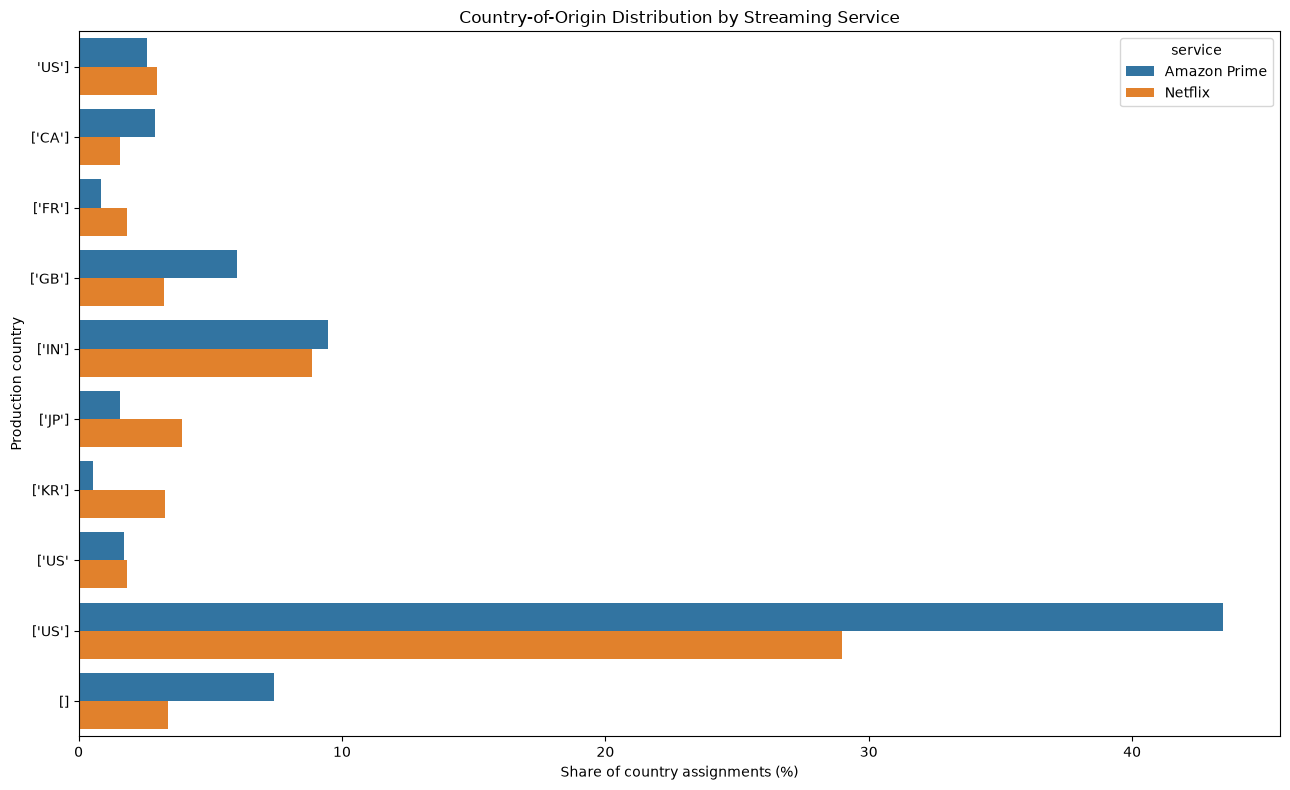

In [602]:
# Find the 10 most common countries across both services
top_countries = (
    country_counts.groupby("production_countries")["titles"]
    .sum()
    .nlargest(10)
    .index
)

plot_data = country_counts[
    country_counts["production_countries"].isin(top_countries)
]

plt.figure(figsize=(13, 8))

sns.barplot(
    data=plot_data,
    x="percentage",
    y="production_countries",
    hue="service"
)

plt.title("Country-of-Origin Distribution by Streaming Service")
plt.xlabel("Share of country assignments (%)")
plt.ylabel("Production country")
plt.tight_layout()
plt.show()

## 8.2 Measure concentration across all countries using Herfindahl–Hirschman Index (HHI).

In [603]:
country_counts["share"] = (
    country_counts["titles"]
    / country_counts.groupby("service")["titles"].transform("sum")
)

country_counts["squared_share"] = country_counts["share"] ** 2

country_hhi = (
    country_counts.groupby("service")["squared_share"]
    .sum()
    .rename("HHI")
)

print(country_hhi.round(4))

service
Amazon Prime    0.2101
Netflix         0.1013
Name: HHI, dtype: float64


note: Amazon Prime had an HHI of 0.2101, compared with 0.1013 for Netflix. This indicates that Amazon Prime’s catalogue is more concentrated among a smaller number of production countries, whereas Netflix’s catalogue has a more geographically distributed production-country profile. The results therefore suggest that Netflix exhibits greater geographical diversity than Amazon Prime in the catalogues analysed.